# 🔮 FORECAST_garch_out_of_sample — Prediksi Volatilitas H+1..H+N (GARCH(1,1))
## Tesis: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi LQ45
**Ilda Nurida — 6032251068 | Pembimbing: Dr. Ir. Ahmad Saikhu, S.Si, MT.**

### 🎯 Tujuan
Menghasilkan **ramalan volatilitas di luar data historis** (di luar `dataset_test`) menggunakan model **GARCH(1,1)** yang di-*refit* pada seluruh data historis yang tersedia (train + test) — pasangan dari `FORECAST_out_of_sample.ipynb` (XGBoost & LSTM), supaya forecast H+1 tiga model (GARCH vs XGBoost vs LSTM) bisa dibandingkan langsung di Bab 4/5 tesis.

### ℹ️ Kenapa GARCH Berbeda dari XGBoost/LSTM di Sini
GARCH **tidak butuh** fitur eksogen (RSI, Stochastic, sentimen, dst) — hanya `Log_Return` historis (univariate). Konsekuensinya:
- **H+1**: identik konsepnya dengan XGBoost/LSTM — fit pakai semua data historis s/d hari terakhir, forecast 1 hari ke depan. ✅ Valid.
- **H+2 s/d H+N**: GARCH punya formula **analitik** untuk multi-step-ahead conditional variance (bukan rekursif "membekukan" fitur seperti LSTM). Ini justru **kelebihan** GARCH — proyeksi H+2..H+N tetap konsisten secara matematis dengan model yang sama, TANPA asumsi "pasar tetap" pada fitur teknikal/sentimen (karena GARCH memang tidak memakainya).
- **Namun tetap ada keterbatasan**: proyeksi H+2..H+N mengasumsikan parameter GARCH (ω, α, β) hasil fit hari ini **konstan** ke depan, dan volatilitas jangka panjang akan menuju rata-rata tak bersyarat (*mean-reverting*) — bukan skenario "kejutan" (shock) baru. Tetap tandai sebagai **proyeksi**, bukan kepastian.

| Horizon | Validitas | Sumber Ketidakpastian |
|---|---|---|
| **H+1** (besok) | ✅ **Valid penuh** — sama seperti evaluasi walk-forward test set | Parameter GARCH hasil fit data s/d hari ini |
| **H+2 s/d H+N** | ✅ **Valid secara model** (formula analitik GARCH), ⚠️ tapi asumsikan tidak ada kejutan baru & parameter konstan | Forecast variance konvergen ke rata-rata jangka panjang (mean-reversion) |


---
## ⚙️ CELL 1 — Import, Konfigurasi Path (identik `MODEL_garch.ipynb` / `FORECAST_out_of_sample.ipynb`)

In [1]:

import os, warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from arch import arch_model
except ImportError:
    raise ImportError("Library 'arch' belum terinstall. Jalankan: pip install arch")

SEED = 42
np.random.seed(SEED)

# ── ROOT auto-detect (identik notebook lain) ──
ROOT = Path(os.getcwd())
for _ in range(6):
    if (ROOT / '03_dataset').exists(): break
    ROOT = ROOT.parent
if not (ROOT / '03_dataset').exists():
    ROOT = Path(r'e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
                r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026')

DIR_PROCESSED = ROOT / '03_dataset' / 'processed'
DIR_FINAL     = ROOT / '03_dataset' / 'final'
DIR_TABEL     = ROOT / '06_dokumen_tesis' / 'tabel'
DIR_GAMBAR    = ROOT / '06_dokumen_tesis' / 'gambar' / 'model'
for d in (DIR_TABEL, DIR_GAMBAR):
    d.mkdir(parents=True, exist_ok=True)

URUTAN_EMITEN   = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']
KOLOM_Y         = 'Volatilitas_Target'   # basis kuantil risiko, sama dgn pipeline lain
N_HARI_FORECAST = 5                       # H+1..H+N (N_HARI_FORECAST) via forecast analitik GARCH

def muat_csv(path, **kw):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'File TIDAK ADA: {path.resolve()}')
    df = pd.read_csv(path, **kw)
    print(f'LOAD  : {path.resolve()}  ({len(df):,} baris x {df.shape[1]} kolom)')
    return df

print('=' * 70)
print('  🔮 FORECAST GARCH OUT-OF-SAMPLE — KONFIGURASI SIAP')
print('=' * 70)
print(f'ROOT             : {ROOT}')
print(f'Emiten           : {URUTAN_EMITEN}')
print(f'KOLOM_Y          : {KOLOM_Y}')
print(f'N_HARI_FORECAST  : {N_HARI_FORECAST} (H+1..H+{N_HARI_FORECAST})')
print('=' * 70)


  🔮 FORECAST GARCH OUT-OF-SAMPLE — KONFIGURASI SIAP
ROOT             : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
Emiten           : ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']
KOLOM_Y          : Volatilitas_Target
N_HARI_FORECAST  : 5 (H+1..H+5)


---
## 🔧 CELL 2 — Fungsi Bantu: Klasifikasi Risiko (identik `FORECAST_out_of_sample.ipynb`)

In [2]:

def hitung_threshold_risiko(vol_historis_series, q_low=0.33, q_high=0.66):
    '''Threshold kuantil 33%/66% dari distribusi HISTORIS Volatilitas_Target
    untuk SATU emiten (per-emiten, bukan global) -- identik notebook forecast ML,
    supaya kategori risiko GARCH bisa dibandingkan apple-to-apple.'''
    data = vol_historis_series.dropna()
    if data.empty:
        raise ValueError('Data historis volatilitas kosong -- cek filter emiten.')
    return data.quantile(q_low), data.quantile(q_high)


def kategori_risiko(vol, vol_historis_series):
    q33, q66 = hitung_threshold_risiko(vol_historis_series)
    if vol < q33:
        return 'Low Risk'
    elif vol < q66:
        return 'Medium Risk'
    else:
        return 'High Risk'

print('✅ Fungsi bantu siap (klasifikasi risiko kuantil per-emiten, identik pipeline ML).')


✅ Fungsi bantu siap (klasifikasi risiko kuantil per-emiten, identik pipeline ML).


---
## 📂 CELL 3 — Muat Seluruh Riwayat `Log_Return` per Emiten (train + test)

Berbeda dari `MODEL_garch.ipynb` (yang fit HANYA sampai `n_train` lalu walk-forward di test), di sini GARCH di-fit ulang memakai **seluruh data historis yang ada** (train+test, s/d hari bursa terakhir) — supaya forecast H+1 benar-benar "besok" di luar seluruh data yang dimiliki, sama seperti perlakuan XGBoost/LSTM di `FORECAST_out_of_sample.ipynb`.

In [3]:

print('=' * 70)
print('  📂 CELL 3 — MUAT DATA TERBARU PER EMITEN')
print('=' * 70)

df_tek = muat_csv(DIR_PROCESSED / 'technical_features.csv')
df_tek['Date'] = pd.to_datetime(df_tek['Date'])

dict_hist = {}   # {emiten: {'log_return':..., 'y_hist':..., 'dates':..., 'tgl_terakhir':...}}

for emiten in URUTAN_EMITEN:
    d = df_tek[df_tek['Emiten'] == emiten].sort_values('Date').reset_index(drop=True)
    d = d.dropna(subset=['Log_Return', KOLOM_Y]).reset_index(drop=True)

    if len(d) < 50:
        print(f'  ⚠️  {emiten}: cuma {len(d)} baris valid, skip')
        continue

    dict_hist[emiten] = {
        'log_return': d['Log_Return'].values,
        'y_hist': d[KOLOM_Y],
        'dates': d['Date'].values,
    }
    tgl_terakhir = pd.Timestamp(d['Date'].values[-1]).date()
    print(f'  ✅ {emiten:<5}: total={len(d):4d} baris | data s/d {tgl_terakhir} siap utk forecast H+1')

print(f'\nTotal emiten siap: {len(dict_hist)}/{len(URUTAN_EMITEN)}')


  📂 CELL 3 — MUAT DATA TERBARU PER EMITEN
LOAD  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\technical_features.csv  (7,315 baris x 25 kolom)
  ✅ ADRO : total=1045 baris | data s/d 2026-06-15 siap utk forecast H+1
  ✅ ADMR : total=1045 baris | data s/d 2026-06-15 siap utk forecast H+1
  ✅ ITMG : total=1045 baris | data s/d 2026-06-15 siap utk forecast H+1
  ✅ PTBA : total=1045 baris | data s/d 2026-06-15 siap utk forecast H+1
  ✅ MEDC : total=1045 baris | data s/d 2026-06-15 siap utk forecast H+1
  ✅ AKRA : total=1045 baris | data s/d 2026-06-15 siap utk forecast H+1
  ✅ PGAS : total=1045 baris | data s/d 2026-06-15 siap utk forecast H+1

Total emiten siap: 7/7


---
## 📈 CELL 4 — Fit GARCH(1,1) Final (Seluruh Data) & Forecast H+1..H+N

Satu fit terakhir per emiten (bukan walk-forward, karena tujuan di sini adalah forecast ke depan, bukan evaluasi historis). Memakai `forecast(horizon=N_HARI_FORECAST, reindex=False)` — proyeksi analitik multi-step conditional variance milik GARCH, konsisten secara matematis (bukan rekursif "fitur dibekukan" seperti LSTM).

In [4]:

print('=' * 70)
print('  📈 CELL 4 — FIT GARCH(1,1) FINAL & FORECAST H+1..H+N')
print('=' * 70)

hasil_garch_forecast = {}

for emiten in dict_hist:
    d = dict_hist[emiten]
    data_pct = d['log_return'] * 100   # skala %, stabilitas numerik arch (identik MODEL_garch)

    am = arch_model(data_pct, vol='Garch', p=1, q=1, dist='normal', mean='Zero')
    try:
        fit = am.fit(disp='off', show_warning=False)
    except Exception as e:
        print(f'  ❌ {emiten}: gagal fit GARCH ({e}), skip')
        continue

    fc = fit.forecast(horizon=N_HARI_FORECAST, reindex=False)
    vol_pred = np.sqrt(fc.variance.values[-1, :]) / 100   # kembali ke skala asli, shape (N_HARI_FORECAST,)

    tgl_basis = pd.Timestamp(d['dates'][-1])
    proyeksi = pd.DataFrame({
        'H': np.arange(1, N_HARI_FORECAST + 1),
        'Tanggal_Estimasi': [tgl_basis + pd.Timedelta(days=h) for h in range(1, N_HARI_FORECAST + 1)],
        'Vol_Prediksi': vol_pred,
    })

    hasil_garch_forecast[emiten] = {
        'Tanggal_Basis': tgl_basis,
        'params': fit.params.to_dict(),
        'proyeksi': proyeksi,
        'Vol_Prediksi_H1': float(vol_pred[0]),
    }

    ringkas = ' | '.join(f"H+{h}={v:.5f}" for h, v in zip(proyeksi['H'], proyeksi['Vol_Prediksi']))
    print(f'  ✅ {emiten:<5}: basis={tgl_basis.date()} -> {ringkas}')

print(f'\nTotal diforecast: {len(hasil_garch_forecast)} emiten')


  📈 CELL 4 — FIT GARCH(1,1) FINAL & FORECAST H+1..H+N
  ✅ ADRO : basis=2026-06-15 -> H+1=0.02486 | H+2=0.02521 | H+3=0.02549 | H+4=0.02571 | H+5=0.02588
  ✅ ADMR : basis=2026-06-15 -> H+1=0.04048 | H+2=0.04039 | H+3=0.04030 | H+4=0.04022 | H+5=0.04013
  ✅ ITMG : basis=2026-06-15 -> H+1=0.02401 | H+2=0.02400 | H+3=0.02399 | H+4=0.02399 | H+5=0.02398
  ✅ PTBA : basis=2026-06-15 -> H+1=0.02886 | H+2=0.02872 | H+3=0.02858 | H+4=0.02844 | H+5=0.02831
  ✅ MEDC : basis=2026-06-15 -> H+1=0.03690 | H+2=0.03674 | H+3=0.03659 | H+4=0.03643 | H+5=0.03629
  ✅ AKRA : basis=2026-06-15 -> H+1=0.02771 | H+2=0.02769 | H+3=0.02767 | H+4=0.02764 | H+5=0.02762
  ✅ PGAS : basis=2026-06-15 -> H+1=0.03079 | H+2=0.02972 | H+3=0.02874 | H+4=0.02786 | H+5=0.02707

Total diforecast: 7 emiten


---
## 📋 CELL 5 — Tabel Ringkasan Forecast H+1 (GARCH) + Klasifikasi Risiko (→ Tabel 4.X Tesis)

Format kolom disamakan dengan `tabel_forecast_h1.csv` (XGBoost/LSTM) supaya mudah digabung jadi tabel 3-way di Bab 4/5.

In [5]:

print('=' * 70)
print('  FORECAST H+1 — GARCH(1,1) + KLASIFIKASI RISIKO')
print('=' * 70)

baris = []
for emiten in URUTAN_EMITEN:
    if emiten not in hasil_garch_forecast:
        continue
    r = hasil_garch_forecast[emiten]
    d_hist = dict_hist[emiten]['y_hist']   # basis kuantil: Volatilitas_Target historis (realized vol)

    v_h1 = r['Vol_Prediksi_H1']
    q33, q66 = hitung_threshold_risiko(d_hist)
    risiko = kategori_risiko(v_h1, d_hist)

    print(f"Emiten               : {emiten}")
    print(f"Prediksi Volatilitas : GARCH(1,1)={v_h1:.4f}")
    print(f"Kategori Risiko      : {risiko}  (threshold Q33={q33:.4f}, Q66={q66:.4f})")
    print(f"Parameter GARCH      : omega={r['params'].get('omega', np.nan):.5f}, "
          f"alpha[1]={r['params'].get('alpha[1]', np.nan):.4f}, beta[1]={r['params'].get('beta[1]', np.nan):.4f}")
    print('-' * 70)

    baris.append({
        'Emiten': emiten,
        'Basis (hari terakhir data)': r['Tanggal_Basis'].date(),
        'Vol_Prediksi_GARCH_H1': round(v_h1, 6),
        'Threshold_Q33': round(q33, 6),
        'Threshold_Q66': round(q66, 6),
        'Kategori_Risiko_GARCH': risiko,
        'omega': round(r['params'].get('omega', np.nan), 6),
        'alpha1': round(r['params'].get('alpha[1]', np.nan), 6),
        'beta1': round(r['params'].get('beta[1]', np.nan), 6),
    })

df_forecast_garch_h1 = pd.DataFrame(baris)
pd.set_option('display.width', 220, 'display.max_columns', None)
print()
print(df_forecast_garch_h1.to_string(index=False))

path_out = DIR_TABEL / 'tabel_forecast_garch_h1.csv'
df_forecast_garch_h1.to_csv(path_out, index=False, encoding='utf-8-sig')
print(f"\n💾 Tabel disimpan: {path_out}")
print('\n⚠️  Ini prediksi H+1 (1 hari bursa ke depan) dari GARCH(1,1) fit pada SELURUH data historis --')
print('   VALID PENUH, bisa dibandingkan langsung dgn tabel_forecast_h1.csv (XGBoost/LSTM).')


  FORECAST H+1 — GARCH(1,1) + KLASIFIKASI RISIKO
Emiten               : ADRO
Prediksi Volatilitas : GARCH(1,1)=0.0249
Kategori Risiko      : Medium Risk  (threshold Q33=0.0200, Q66=0.0260)
Parameter GARCH      : omega=1.45954, alpha[1]=0.1167, beta[1]=0.6758
----------------------------------------------------------------------
Emiten               : ADMR
Prediksi Volatilitas : GARCH(1,1)=0.0405
Kategori Risiko      : High Risk  (threshold Q33=0.0278, Q66=0.0371)
Parameter GARCH      : omega=0.16222, alpha[1]=0.0183, beta[1]=0.9674
----------------------------------------------------------------------
Emiten               : ITMG
Prediksi Volatilitas : GARCH(1,1)=0.0240
Kategori Risiko      : High Risk  (threshold Q33=0.0131, Q66=0.0209)
Parameter GARCH      : omega=0.02618, alpha[1]=0.0588, beta[1]=0.9359
----------------------------------------------------------------------
Emiten               : PTBA
Prediksi Volatilitas : GARCH(1,1)=0.0289
Kategori Risiko      : High Risk  (threshol

---
## 🔁 CELL 6 — Tabel Proyeksi H+1..H+N (GARCH, Analitik Multi-Step)

Beda dengan mode rekursif LSTM (`CELL 7` di `FORECAST_out_of_sample.ipynb`) yang membekukan fitur teknikal/sentimen, proyeksi GARCH ini murni formula matematis `σ²_{t+h}` dari model yang sama — tetap ditandai sebagai **proyeksi ke depan** (bukan observasi), karena mengasumsikan tidak ada kejutan/shock baru dan parameter konstan.

In [6]:

print('=' * 70)
print(f'  🔁 CELL 6 — PROYEKSI H+1..H+{N_HARI_FORECAST} (GARCH, ANALITIK)')
print('=' * 70)

df_proyeksi_all = pd.concat(
    [df.assign(Emiten=e) for e, r in hasil_garch_forecast.items() for df in [r['proyeksi']]],
    ignore_index=True
)[['Emiten', 'H', 'Tanggal_Estimasi', 'Vol_Prediksi']]

pd.set_option('display.width', 200, 'display.max_columns', None)
print(df_proyeksi_all.to_string(index=False))

path_rek = DIR_TABEL / 'tabel_forecast_garch_multistep.csv'
df_proyeksi_all.to_csv(path_rek, index=False, encoding='utf-8-sig')
print(f"\n💾 Tabel disimpan: {path_rek}")
print('ℹ️  Catatan: volatilitas GARCH multi-step secara teoretis akan konvergen (mean-reverting)')
print('   ke rata-rata tak bersyarat sqrt(omega/(1-alpha-beta)) seiring H membesar.')


  🔁 CELL 6 — PROYEKSI H+1..H+5 (GARCH, ANALITIK)
Emiten  H Tanggal_Estimasi  Vol_Prediksi
  ADRO  1       2026-06-16      0.024859
  ADRO  2       2026-06-17      0.025213
  ADRO  3       2026-06-18      0.025491
  ADRO  4       2026-06-19      0.025709
  ADRO  5       2026-06-20      0.025880
  ADMR  1       2026-06-16      0.040476
  ADMR  2       2026-06-17      0.040389
  ADMR  3       2026-06-18      0.040302
  ADMR  4       2026-06-19      0.040216
  ADMR  5       2026-06-20      0.040131
  ITMG  1       2026-06-16      0.024011
  ITMG  2       2026-06-17      0.024002
  ITMG  3       2026-06-18      0.023994
  ITMG  4       2026-06-19      0.023985
  ITMG  5       2026-06-20      0.023977
  PTBA  1       2026-06-16      0.028858
  PTBA  2       2026-06-17      0.028716
  PTBA  3       2026-06-18      0.028577
  PTBA  4       2026-06-19      0.028441
  PTBA  5       2026-06-20      0.028309
  MEDC  1       2026-06-16      0.036904
  MEDC  2       2026-06-17      0.036743
  MEDC  

---
## 📊 CELL 7 — Visualisasi: Historis + Forecast GARCH H+1..H+N per Emiten (→ Gambar 4.X)

  📊 VISUALISASI FORECAST GARCH PER EMITEN


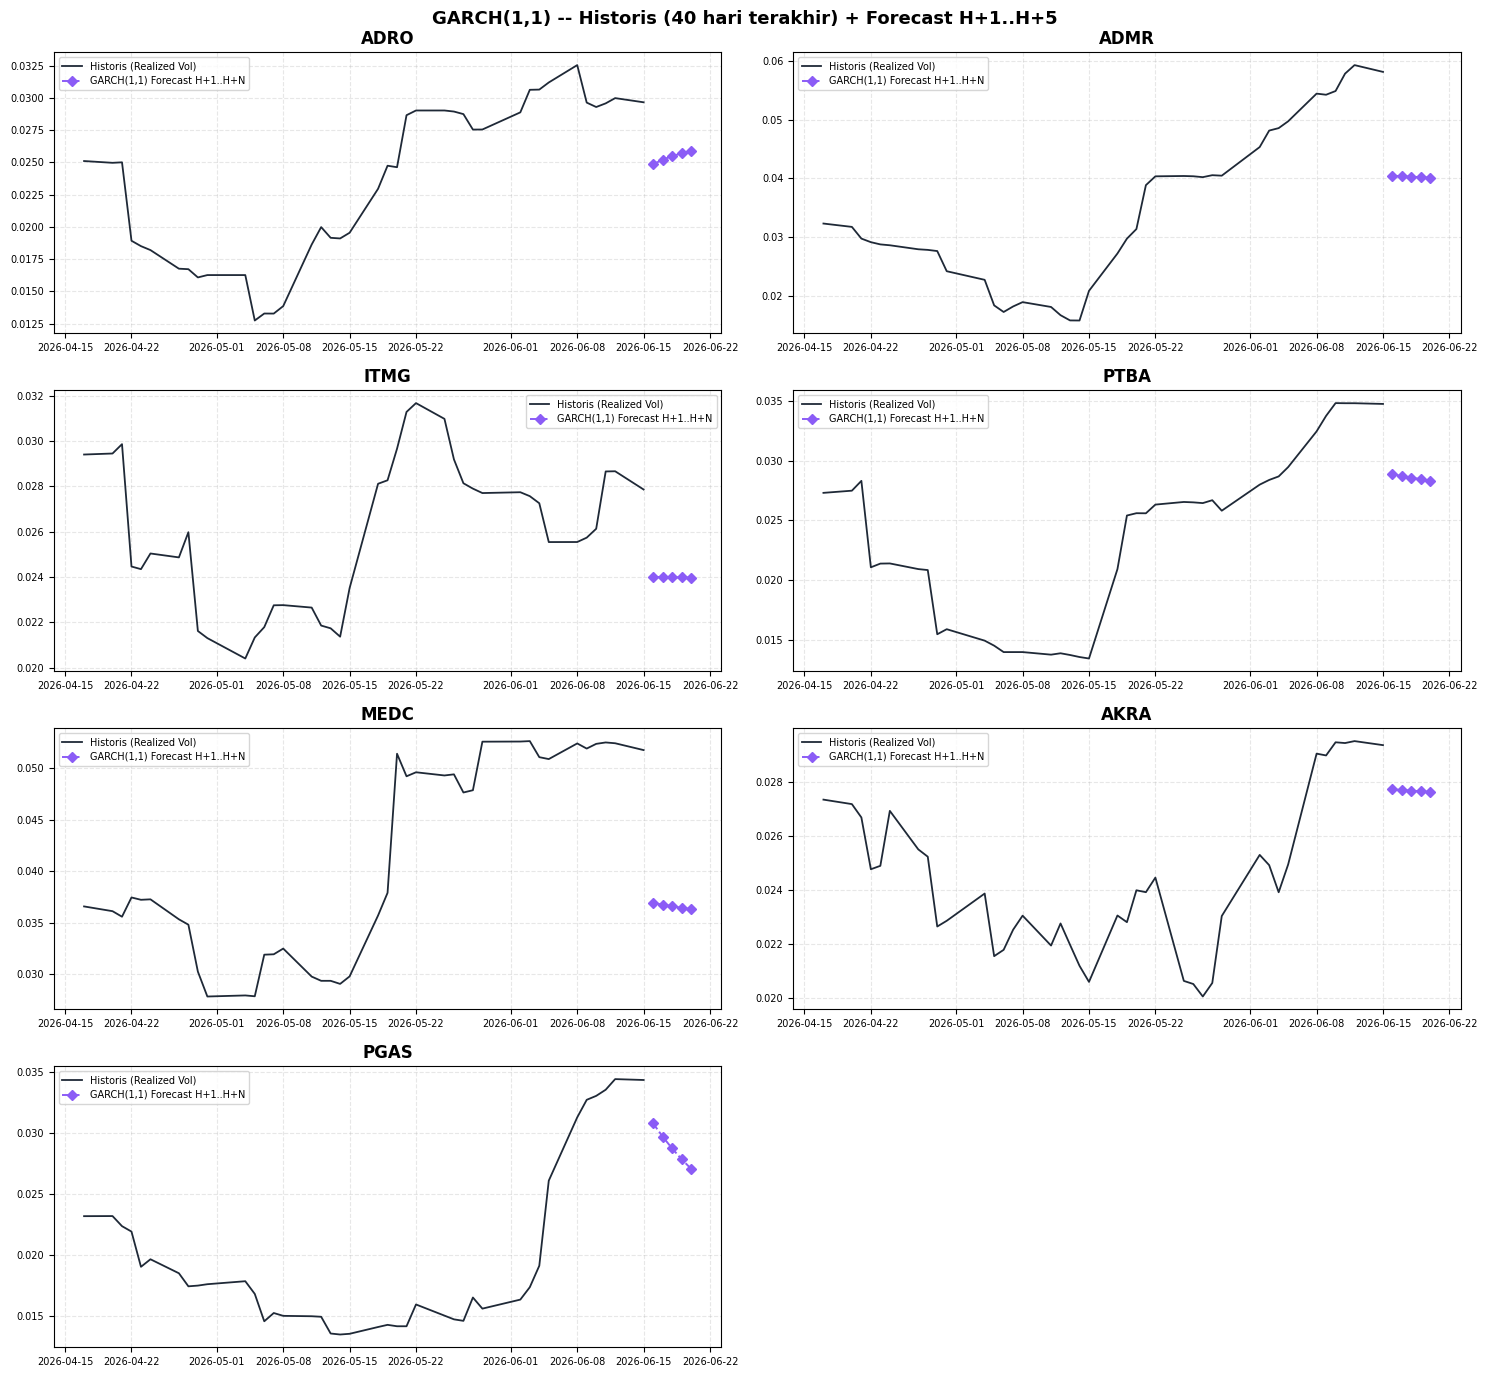

💾 Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\model\gambar_forecast_garch_out_of_sample.png

✅ FORECAST GARCH OUT-OF-SAMPLE SELESAI
   H+1 (valid, sebanding XGB/LSTM)     : tabel_forecast_garch_h1.csv
   H+1..H+5 (analitik, mean-reverting) : tabel_forecast_garch_multistep.csv


In [7]:

print('=' * 70)
print('  📊 VISUALISASI FORECAST GARCH PER EMITEN')
print('=' * 70)

emiten_ok = [e for e in URUTAN_EMITEN if e in hasil_garch_forecast]
ncol = 2; nrow = int(np.ceil(len(emiten_ok) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.5 * nrow))
axes = np.array(axes).ravel()

for ax, emiten in zip(axes, emiten_ok):
    d_hist_plot = df_tek[df_tek['Emiten'] == emiten].sort_values('Date').tail(40)
    ax.plot(d_hist_plot['Date'], d_hist_plot[KOLOM_Y], color='#1f2937', lw=1.3, label='Historis (Realized Vol)')

    dfr = hasil_garch_forecast[emiten]['proyeksi']
    ax.plot(dfr['Tanggal_Estimasi'], dfr['Vol_Prediksi'],
            color='#8B5CF6', lw=1.4, linestyle='--', marker='D', markersize=5,
            label='GARCH(1,1) Forecast H+1..H+N')

    ax.set_title(emiten, fontweight='bold')
    ax.legend(fontsize=7); ax.tick_params(labelsize=7)
    ax.grid(alpha=0.3, linestyle='--')

for ax in axes[len(emiten_ok):]:
    ax.axis('off')

plt.suptitle(f'GARCH(1,1) -- Historis (40 hari terakhir) + Forecast H+1..H+{N_HARI_FORECAST}',
             fontweight='bold', fontsize=13)
plt.tight_layout()
path_fig = DIR_GAMBAR / 'gambar_forecast_garch_out_of_sample.png'
plt.savefig(path_fig, dpi=150, bbox_inches='tight')
plt.show()
print(f"💾 Gambar disimpan: {path_fig}")

print()
print('=' * 70)
print('✅ FORECAST GARCH OUT-OF-SAMPLE SELESAI')
print(f'   H+1 (valid, sebanding XGB/LSTM)     : tabel_forecast_garch_h1.csv')
print(f'   H+1..H+{N_HARI_FORECAST} (analitik, mean-reverting) : tabel_forecast_garch_multistep.csv')
print('=' * 70)
